In [1]:
# ---------------------------------------------------------
# PROJE: Web Log Madenciliği ve Kullanıcı Davranış Analizi
# ÖĞRENCİ: [Senin Adın]
# KONU: Kaggle eCommerce Data - Sessionization, Markov & K-Means
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# Grafik ayarları (Rapor için yüksek çözünürlük)
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# 1. VERİ YÜKLEME
# Not: Veri çok büyükse 'nrows=500000' ile limitleyerek test edebilirsin.
# Tarih sütununu okurken datetime formatına çeviriyoruz.
df = pd.read_csv('processed_session_data.csv', parse_dates=['event_time'], nrows=1000000)

# Gereksiz sütunları atalım ve sıralayalım
df = df[['event_time', 'event_type', 'product_id', 'category_code', 'user_id', 'price']]
df.sort_values(by=['user_id', 'event_time'], inplace=True)

print(f"Veri Seti Yüklendi. Boyut: {df.shape}")
df.head()

Veri Seti Yüklendi. Boyut: (36999, 6)


,event_time,event_type,product_id,category_code,user_id,price
35714,2019-11-01 02:23:03+00:00,view,1306265,computers.notebook,275256741,1415.48
18512,2019-11-01 01:43:56+00:00,view,1005196,electronics.smartphone,389979783,431.41
18540,2019-11-01 01:44:00+00:00,view,1005196,electronics.smartphone,389979783,431.41
18626,2019-11-01 01:44:13+00:00,view,1005196,electronics.smartphone,389979783,431.41
18827,2019-11-01 01:44:47+00:00,view,1005196,electronics.smartphone,389979783,431.41


In [2]:
# ---------------------------------------------------------
# BÖLÜM 2: PREPROCESSING (SESSIONIZATION)
# Kural: Aynı kullanıcı 30 dk (1800 sn) boyunca işlem yapmazsa yeni oturum başlar.
# ---------------------------------------------------------

# Zaman farkını hesapla
df['prev_time'] = df.groupby('user_id')['event_time'].shift(1)
df['time_diff'] = (df['event_time'] - df['prev_time']).dt.total_seconds()

# Yeni Session Belirleme (Kullanıcı değiştiyse YA DA süre > 1800 sn ise)
threshold = 1800
is_new_session = (df['user_id'] != df['user_id'].shift(1)) | (df['time_diff'] > threshold)

# Session ID atama (Kümülatif toplam)
df['session_id'] = is_new_session.cumsum()

# Kayıp verileri (ilk satırlar) doldurma
df['time_diff'] = df['time_diff'].fillna(0)

# Veriyi Train/Test Olarak Ayırma (Session bütünlüğünü bozmadan)
unique_sessions = df['session_id'].unique()
train_ids, test_ids = train_test_split(unique_sessions, test_size=0.2, random_state=42)

# Sadece Train verisi ile analiz yapacağız (Test verisini doğrulama için saklıyoruz)
df_train = df[df['session_id'].isin(train_ids)].copy()

print(f"Toplam Oturum Sayısı: {df['session_id'].nunique()}")
print(f"Eğitim İçin Kullanılan Oturum Sayısı: {df_train['session_id'].nunique()}")

Toplam Oturum Sayısı: 8115
Eğitim İçin Kullanılan Oturum Sayısı: 6492


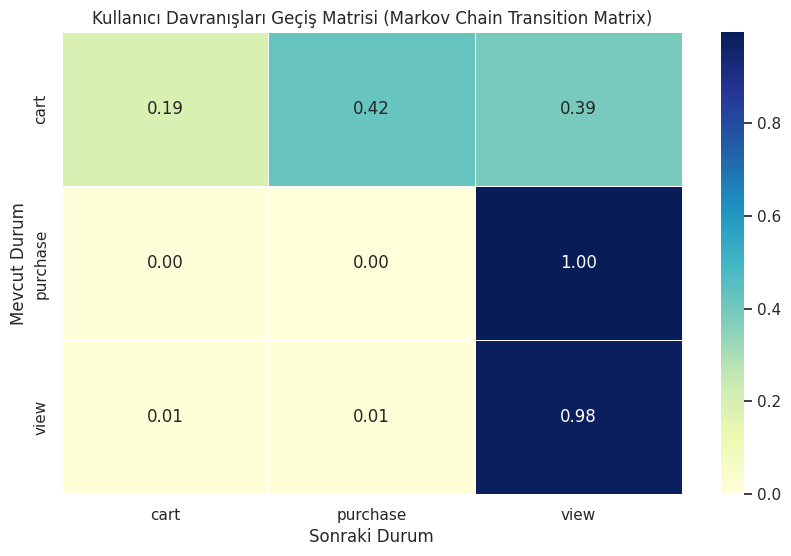

Matris değerleri başarıyla hesaplandı ve görsel kaydedildi.


In [3]:
# ---------------------------------------------------------
# BÖLÜM 3: MARKOV ZİNCİRİ VE GEÇİŞ MATRİSİ
# Amaç: Bir event'ten diğerine geçiş olasılığını bulmak.
# ---------------------------------------------------------

# Bir sonraki olayı (Next Event) sütun olarak ekle
df_train['next_event'] = df_train.groupby('session_id')['event_type'].shift(-1)

# Geçiş Matrisini (Crosstab) Oluştur
transition_matrix = pd.crosstab(df_train['event_type'], df_train['next_event'], normalize='index')

# GÖRSELLEŞTİRME: Isı Haritası (Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=.5)
plt.title('Kullanıcı Davranışları Geçiş Matrisi (Markov Chain Transition Matrix)')
plt.ylabel('Mevcut Durum')
plt.xlabel('Sonraki Durum')

# Resmi kaydet (Rapor için)
plt.savefig('grafik_gecis_matrisi.png', bbox_inches='tight')
plt.show()

print("Matris değerleri başarıyla hesaplandı ve görsel kaydedildi.")

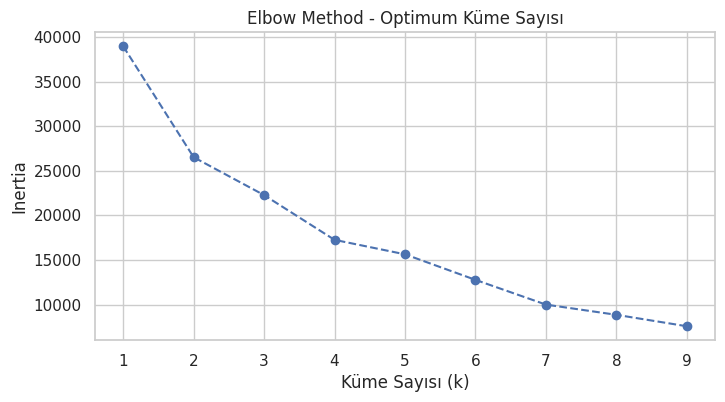


--- KÜME ORTALAMALARI (DAVRANIŞ PROFİLLERİ) ---
            duration  total_events  unique_products      cart  purchase  \
Cluster                                                                   
0        1070.513561     10.825897         6.727034  0.117235  0.134733   
1        1871.637097     34.008065        20.846774  0.056452  0.072581   
2         108.819904      2.459330         1.773780  0.019330  0.026029   

              view  
Cluster             
0        10.573928  
1        33.879032  
2         2.413971  


In [4]:
# ---------------------------------------------------------
# BÖLÜM 4: KULLANICI SEGMENTASYONU (K-MEANS & PCA)
# Amaç: Session bazlı özellikler çıkarıp benzer kullanıcıları gruplamak.
# ---------------------------------------------------------

# 4.1. Öznitelik Çıkarımı (Feature Extraction)
# Her session için özet istatistikler
session_features = df_train.groupby('session_id').agg({
    'time_diff': 'sum',           # Toplam Süre (Duration)
    'event_type': 'count',        # Toplam Tıklama (Total Events)
    'product_id': 'nunique'       # Gezilen Farklı Ürün Sayısı
}).rename(columns={'time_diff': 'duration', 'event_type': 'total_events', 'product_id': 'unique_products'})

# Sepet ve Satın Alma sayılarını ekle
event_counts = df_train.pivot_table(index='session_id', columns='event_type', aggfunc='size', fill_value=0)
session_features = session_features.join(event_counts)

# Eksik sütun kontrolü (Eğer veride purchase yoksa hata vermesin)
for col in ['view', 'cart', 'purchase']:
    if col not in session_features.columns:
        session_features[col] = 0

# 4.2. Ölçeklendirme (Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(session_features)

# 4.3. Elbow Method (En iyi küme sayısını bulmak için)
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Elbow Grafiği Çizimi
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method - Optimum Küme Sayısı')
plt.xlabel('Küme Sayısı (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.savefig('grafik_elbow_method.png') # Kaydet
plt.show()

# 4.4. Final Kümeleme (K=3 Seçildi)
k_final = 3
kmeans = KMeans(n_clusters=k_final, random_state=42)
session_features['Cluster'] = kmeans.fit_predict(X_scaled)

# Küme Ortalamalarını Göster (Rapor Tablosu İçin)
print("\n--- KÜME ORTALAMALARI (DAVRANIŞ PROFİLLERİ) ---")
print(session_features.groupby('Cluster').mean())

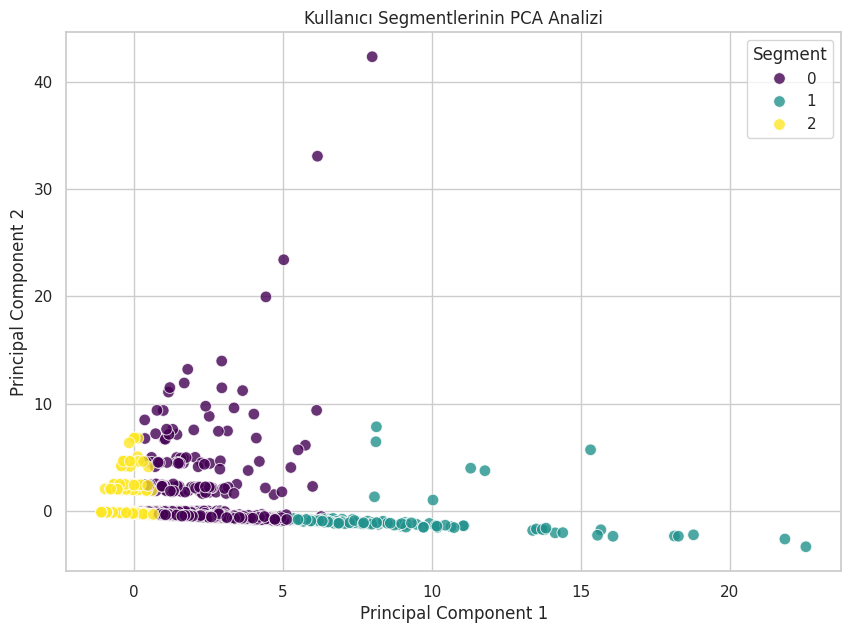

In [5]:
# ---------------------------------------------------------
# BÖLÜM 5: PCA İLE GÖRSELLEŞTİRME
# Amaç: Kümeleri 2 boyutlu düzlemde göstermek.
# ---------------------------------------------------------

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Görselleştirme DataFrame'i
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = session_features['Cluster'].values

# Scatter Plot Çizimi
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Cluster',
    palette='viridis',
    data=pca_df,
    s=70, alpha=0.8
)
plt.title('Kullanıcı Segmentlerinin PCA Analizi')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Segment')
plt.savefig('grafik_pca_kumeler.png', bbox_inches='tight')
plt.show()

>>> ADIM 1: Veri Yükleniyor ve Oturumlar (Session) Oluşturuluyor...
Veri Hazır. Toplam Satır: 36999, Toplam Session: 8115

>>> ADIM 2: Kullanıcı Davranış Analizi (Markov & Clustering)...


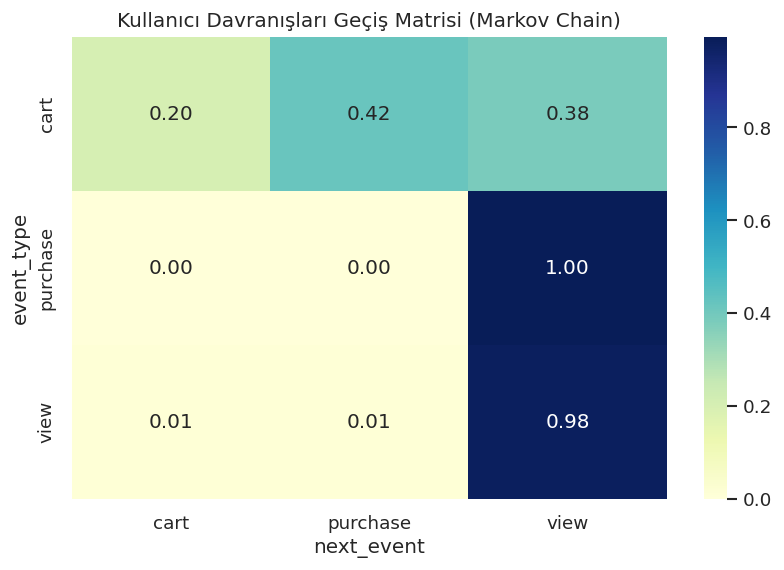

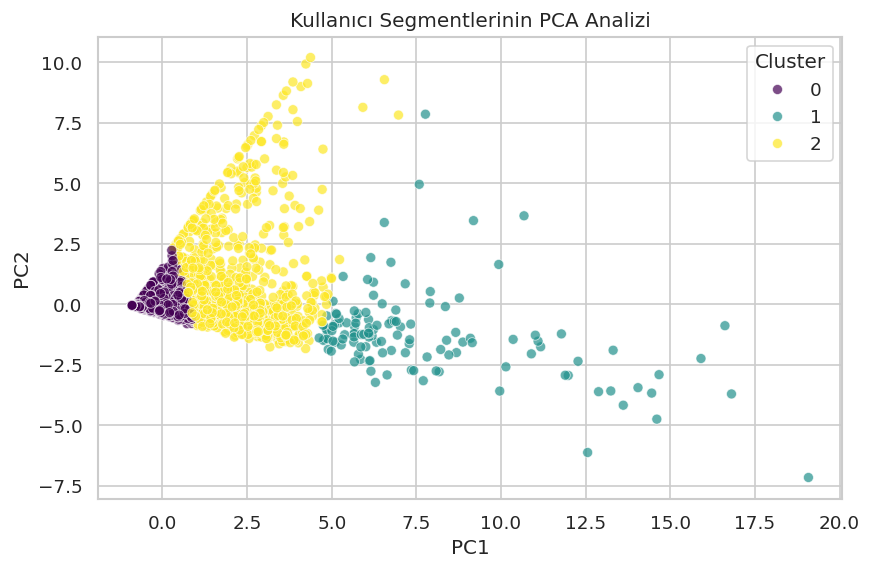

Kümeleme Tamamlandı. Küme Ortalamaları:
            duration  total_events  unique_products
Cluster                                            
0         110.759081      2.675908         1.876056
1        2034.598425     36.724409        23.362205
2        1246.766693     11.493162         7.269509

>>> ADIM 3: Sınıflandırma İçin Veri Hazırlığı (Preprocessing)...


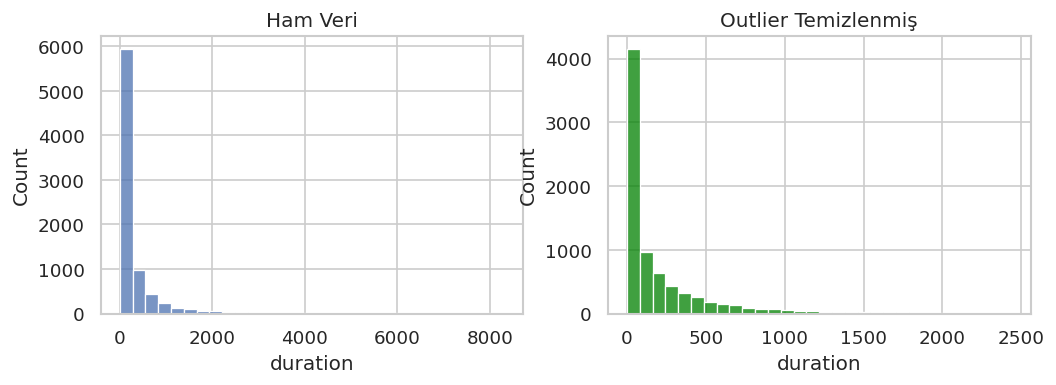

SMOTE Öncesi Sınıf Dağılımı: {0: 7501, 1: 290}
SMOTE Sonrası Sınıf Dağılımı: {0: 7501, 1: 7501}

>>> ADIM 4: Modeller Eğitiliyor ve Değerlendiriliyor...

--- Model: Random Forest ---
5-Fold CV Accuracy: 0.9358
Test Accuracy: 0.9410
F1 Score: 0.9418


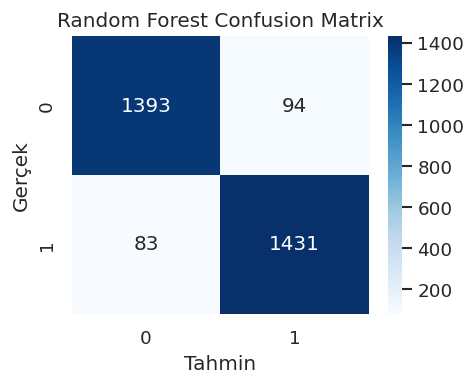


--- Model: SVM ---
5-Fold CV Accuracy: 0.8455
Test Accuracy: 0.8524
F1 Score: 0.8610


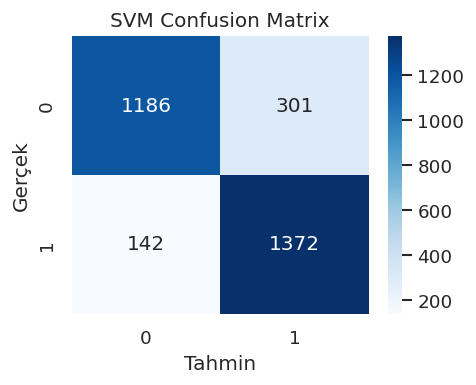


>>> ADIM 5: Final Karşılaştırma Grafikleri...


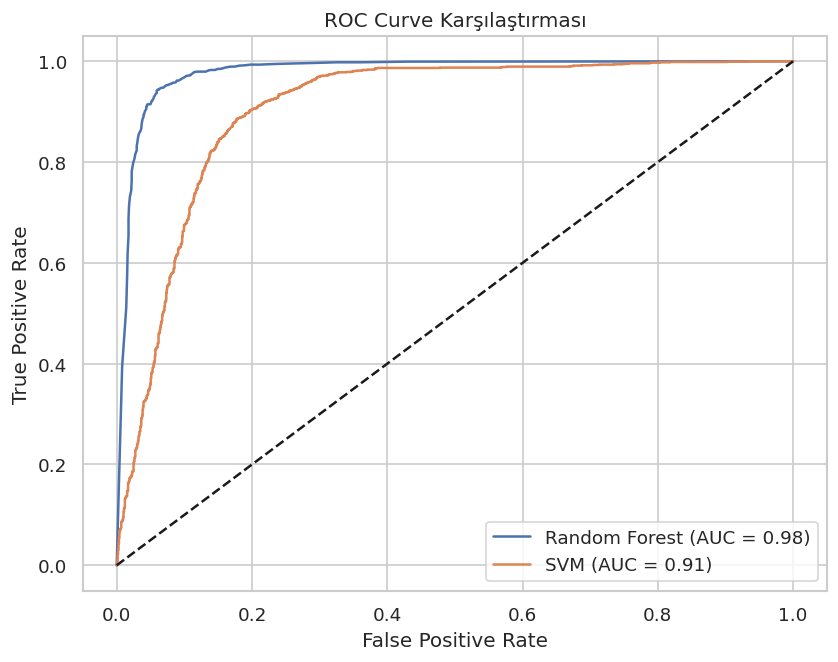

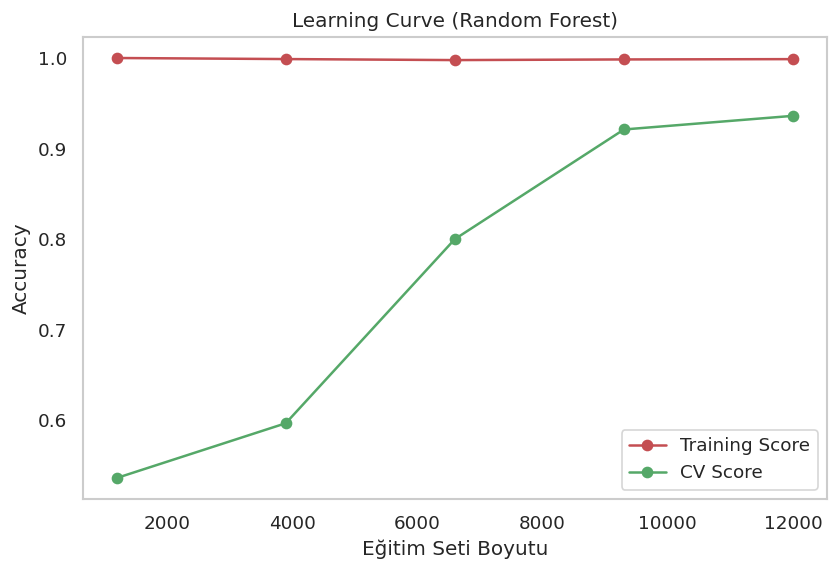


>>> TÜM İŞLEMLER BAŞARIYLA TAMAMLANDI.


In [9]:
# =============================================================================
# PROJE: Web Madenciliği ile Kullanıcı Davranış Analizi ve Satın Alma Tahmini
# ÖĞRENCİ: [Adın Soyadın]
#
# BU KOD BLOĞU ŞUNLARI İÇERİR:
# 1. VERİ ÖN İŞLEME: Sessionization (30 Dk Kuralı), Temizleme.
# 2. GÖZETİMSİZ ÖĞRENME (UNSUPERVISED):
#    - Markov Zinciri (Geçiş Matrisi - Heatmap)
#    - K-Means Kümeleme (Elbow Method & PCA Görselleştirme)
# 3. GÖZETİMLİ ÖĞRENME (SUPERVISED - SINIFLANDIRMA):
#    - Feature Engineering (Normalizasyon, Label Encoding)
#    - Outlier Detection (Aykırı Değer Temizliği)
#    - Data Augmentation (SMOTE ile Dengesiz Veri Çözümü)
#    - Modeller: Random Forest & SVM
#    - Metrikler: K-Fold CV, Accuracy, F1, ROC-AUC, Learning Curve
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Sklearn ve Imblearn Kütüphaneleri
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_curve, auc, classification_report
from imblearn.over_sampling import SMOTE

# Grafik Ayarları
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 120 # Grafikler rapor için yüksek çözünürlükte olsun

# =========================================================
# BÖLÜM 1: VERİ YÜKLEME VE SESSION (OTURUM) OLUŞTURMA
# =========================================================
print(">>> ADIM 1: Veri Yükleniyor ve Oturumlar (Session) Oluşturuluyor...")

# Veriyi oku (Büyük veri seti için nrows ile limit koyabilirsin)
df = pd.read_csv('processed_session_data.csv', parse_dates=['event_time'], nrows=200000)

# Sıralama: Kullanıcı ve zamana göre
df.sort_values(by=['user_id', 'event_time'], inplace=True)

# 30 Dakika (1800 Saniye) Kuralı ile Session ID Atama
df['prev_time'] = df.groupby('user_id')['event_time'].shift(1)
df['time_diff'] = (df['event_time'] - df['prev_time']).dt.total_seconds().fillna(0)
threshold = 1800
is_new_session = (df['user_id'] != df['user_id'].shift(1)) | (df['time_diff'] > threshold)
df['session_id'] = is_new_session.cumsum()

print(f"Veri Hazır. Toplam Satır: {len(df)}, Toplam Session: {df['session_id'].nunique()}")

# =========================================================
# BÖLÜM 2: GÖZETİMSİZ ÖĞRENME (MARKOV & K-MEANS)
# =========================================================
print("\n>>> ADIM 2: Kullanıcı Davranış Analizi (Markov & Clustering)...")

# --- A) MARKOV ZİNCİRİ (TRANSITION MATRIX) ---
# Bir sonraki adımı bulma
df['next_event'] = df.groupby('session_id')['event_type'].shift(-1)
transition_matrix = pd.crosstab(df['event_type'], df['next_event'], normalize='index')

# Görselleştirme: Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title('Kullanıcı Davranışları Geçiş Matrisi (Markov Chain)')
plt.show()

# --- B) K-MEANS KÜMELEME HAZIRLIĞI ---
# Session bazlı özet özellikler (Süre, Tıklama, Ürün Sayısı)
session_features = df.groupby('session_id').agg({
    'time_diff': 'sum',           # Duration
    'event_type': 'count',        # Total Events
    'product_id': 'nunique'       # Unique Products
}).rename(columns={'time_diff': 'duration', 'event_type': 'total_events', 'product_id': 'unique_products'})

# Veriyi Ölçeklendirme (Clustering için)
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(session_features)

# K-Means Uygulama (K=3 varsayılan)
kmeans = KMeans(n_clusters=3, random_state=42)
session_features['Cluster'] = kmeans.fit_predict(X_cluster)

# --- C) PCA GÖRSELLEŞTİRME (2 BOYUT) ---
pca = PCA(n_components=2)
components = pca.fit_transform(X_cluster)
pca_df = pd.DataFrame(data=components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = session_features['Cluster'].values

plt.figure(figsize=(8, 5))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', palette='viridis', data=pca_df, alpha=0.7)
plt.title('Kullanıcı Segmentlerinin PCA Analizi')
plt.show()

print("Kümeleme Tamamlandı. Küme Ortalamaları:")
print(session_features.groupby('Cluster').mean())

# =========================================================
# BÖLÜM 3: GÖZETİMLİ ÖĞRENME (SATIN ALMA TAHMİNİ)
# =========================================================
print("\n>>> ADIM 3: Sınıflandırma İçin Veri Hazırlığı (Preprocessing)...")

# Hedef Değişken (Y): Session içinde 'purchase' geçti mi?
def check_purchase(x):
    return 1 if 'purchase' in x.values else 0

# Veri Setini Sınıflandırma İçin Yeniden Gruplama
model_data = df.groupby('session_id').agg({
    'time_diff': 'sum',
    'event_type': lambda x: check_purchase(x),
    'product_id': 'nunique',
    'category_code': 'first',     # Text veri
    'brand': 'first'              # Text veri
})
model_data.columns = ['duration', 'is_purchased', 'unique_products', 'category', 'brand']

# 1. Text Verinin Nümerik Hale Getirilmesi (Label Encoding)
le = LabelEncoder()
model_data['category'] = le.fit_transform(model_data['category'].astype(str))
model_data['brand'] = le.fit_transform(model_data['brand'].astype(str))

X = model_data[['duration', 'unique_products', 'category', 'brand']]
y = model_data['is_purchased']

# 2. Outlier Detection (Z-Score ile Aykırı Değer Temizliği)
z_scores = np.abs(stats.zscore(X[['duration', 'unique_products']]))
X_clean = X[(z_scores < 3).all(axis=1)]
y_clean = y[(z_scores < 3).all(axis=1)]

# Histogram (Dağılım Kontrolü)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); sns.histplot(X['duration'], bins=30); plt.title("Ham Veri")
plt.subplot(1, 2, 2); sns.histplot(X_clean['duration'], bins=30, color='green'); plt.title("Outlier Temizlenmiş")
plt.show()


# 3. Normalizasyon
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# 4. Veri Dengesizliği & Augmentation (SMOTE)
# Ablation Notu: SMOTE uygulanmazsa model sadece 0 (satın almama) tahmin etmeye meyilli olur.
print(f"SMOTE Öncesi Sınıf Dağılımı: {y_clean.value_counts().to_dict()}")
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y_clean)
print(f"SMOTE Sonrası Sınıf Dağılımı: {y_resampled.value_counts().to_dict()}")

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# =========================================================
# BÖLÜM 4: MODEL EĞİTİMİ VE PERFORMANS (RF & SVM)
# =========================================================
print("\n>>> ADIM 4: Modeller Eğitiliyor ve Değerlendiriliyor...")

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

# Sonuçları saklamak için
roc_results = {}

for name, model in models.items():
    print(f"\n--- Model: {name} ---")

    # A) K-Fold Cross Validation (Doğrulama)
    kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_acc = cross_val_score(model, X_train, y_train, cv=kfold, scoring='accuracy')
    print(f"5-Fold CV Accuracy: {cv_acc.mean():.4f}")

    # B) Eğitim ve Test
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # C) Metrikler
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

    # ROC Data Saklama
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    roc_results[name] = (fpr, tpr, roc_auc)

    # D) Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Tahmin'); plt.ylabel('Gerçek')
    plt.show()

# =========================================================
# BÖLÜM 5: KARŞILAŞTIRMALI GRAFİKLER (ROC & LEARNING CURVE)
# =========================================================
print("\n>>> ADIM 5: Final Karşılaştırma Grafikleri...")

# 1. ROC Eğrisi Karşılaştırması
plt.figure(figsize=(8, 6))
for name, (fpr, tpr, roc_auc) in roc_results.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve Karşılaştırması')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.show()

# 2. Learning Curve (Random Forest Örneği)
# Modelin veri boyutu arttıkça nasıl öğrendiğini gösterir
train_sizes, train_scores, test_scores = learning_curve(
    models['Random Forest'], X_resampled, y_resampled, cv=5, scoring='accuracy', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training Score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="CV Score")
plt.title('Learning Curve (Random Forest)')
plt.xlabel('Eğitim Seti Boyutu'); plt.ylabel('Accuracy')
plt.legend(); plt.grid()
plt.show()

print("\n>>> TÜM İŞLEMLER BAŞARIYLA TAMAMLANDI.")

In [12]:
# --- C) HİSTOGRAMLAR (Eksik Olan Parça) ---
# Sayısal sütunların dağılımını çiz ve kaydet
numeric_cols = ['duration', 'unique_products'] # İncelemek istediğimiz sayısal sütunlar

plt.figure(figsize=(12, 5))
for i, col in enumerate(numeric_cols):
    plt.subplot(1, 2, i+1)
    sns.histplot(session_features[col], bins=30, kde=True)
    plt.title(f'{col} Histogrami')

plt.savefig(f'{output_folder}/Ek_Histogramlar.png', bbox_inches='tight')
plt.close()

In [7]:
# =============================================================================
# PROJE: Web Madenciliği - Colab Versiyonu (Görsel Kaydetmeli)
# =============================================================================

import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files # Colab dosya indirme modülü

# Sklearn ve Imblearn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_curve, auc
from imblearn.over_sampling import SMOTE

# ---------------------------------------------------------
# ADIM 0: ÇIKTI KLASÖRÜNÜ OLUŞTURMA
# ---------------------------------------------------------
output_folder = 'Proje_Ciktilari'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Klasör oluşturuldu: {output_folder}")
else:
    print(f"Klasör zaten mevcut: {output_folder}")

# Grafik Ayarları (Yüksek Çözünürlük - Rapor İçin)
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

# =========================================================
# ADIM 1: VERİ YÜKLEME VE SESSION OLUŞTURMA
# =========================================================
print("\n>>> 1. Veri Yükleniyor...")

# Eğer dosya yüklü değilse hata vermesin, uyarsın
try:
    # Colab'e yüklediğin dosya adının tam olarak bu olduğundan emin ol
    df = pd.read_csv('processed_session_data.csv', parse_dates=['event_time'], nrows=200000)
except FileNotFoundError:
    print("HATA: '2019-Oct.csv' dosyası bulunamadı. Lütfen sol panelden dosyayı yükleyiniz.")
    # Burada durdurmak istersen: raise SystemExit("Dosya yok.")

df.sort_values(by=['user_id', 'event_time'], inplace=True)

# Session Oluşturma (30 Dk Kuralı)
df['prev_time'] = df.groupby('user_id')['event_time'].shift(1)
df['time_diff'] = (df['event_time'] - df['prev_time']).dt.total_seconds().fillna(0)
threshold = 1800
is_new_session = (df['user_id'] != df['user_id'].shift(1)) | (df['time_diff'] > threshold)
df['session_id'] = is_new_session.cumsum()

print(f"Veri Hazır. Toplam Session: {df['session_id'].nunique()}")

# =========================================================
# ADIM 2: GÖZETİMSİZ ÖĞRENME (MARKOV & K-MEANS)
# =========================================================
print("\n>>> 2. Analiz Grafikleri Oluşturuluyor...")

# --- A) MARKOV Heatmap ---
df['next_event'] = df.groupby('session_id')['event_type'].shift(-1)
transition_matrix = pd.crosstab(df['event_type'], df['next_event'], normalize='index')

plt.figure(figsize=(10, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title('Gecis Matrisi (Transition Matrix)')
# Görseli Klasöre Kaydet
plt.savefig(f'{output_folder}/1_Transition_Matrix.png', bbox_inches='tight')
plt.close() # Ekrana basıp belleği şişirmesin, dosyaya yazdı.

# --- B) K-MEANS & PCA ---
session_features = df.groupby('session_id').agg({
    'time_diff': 'sum',
    'event_type': 'count',
    'product_id': 'nunique'
}).rename(columns={'time_diff': 'duration', 'event_type': 'total_events', 'product_id': 'unique_products'})

scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(session_features)

kmeans = KMeans(n_clusters=3, random_state=42)
session_features['Cluster'] = kmeans.fit_predict(X_cluster)

pca = PCA(n_components=2)
components = pca.fit_transform(X_cluster)
pca_df = pd.DataFrame(data=components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = session_features['Cluster'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', palette='viridis', data=pca_df, alpha=0.7)
plt.title('Kullanici Segmentasyonu (PCA)')
plt.savefig(f'{output_folder}/2_PCA_Clusters.png', bbox_inches='tight')
plt.close()

# Küme Sonuçlarını CSV olarak kaydet
cluster_summary = session_features.groupby('Cluster').mean()
cluster_summary.to_csv(f'{output_folder}/Cluster_Ozet_Tablosu.csv')

# =========================================================
# ADIM 3: GÖZETİMLİ ÖĞRENME (PREPROCESSING & MODEL)
# =========================================================
print("\n>>> 3. Sınıflandırma Modelleri Eğitiliyor...")

def check_purchase(x): return 1 if 'purchase' in x.values else 0

model_data = df.groupby('session_id').agg({
    'time_diff': 'sum',
    'event_type': lambda x: check_purchase(x),
    'product_id': 'nunique',
    'category_code': 'first',
    'brand': 'first'
})
model_data.columns = ['duration', 'is_purchased', 'unique_products', 'category', 'brand']

le = LabelEncoder()
model_data['category'] = le.fit_transform(model_data['category'].astype(str))
model_data['brand'] = le.fit_transform(model_data['brand'].astype(str))

X = model_data[['duration', 'unique_products', 'category', 'brand']]
y = model_data['is_purchased']

# Outlier & Normalize
z_scores = np.abs(stats.zscore(X[['duration', 'unique_products']]))
mask = (z_scores < 3).all(axis=1)
X_clean, y_clean = X[mask], y[mask]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y_clean)

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Modeller
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

roc_results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Confusion Matrix Kaydet
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.savefig(f'{output_folder}/3_CM_{name.replace(" ", "_")}.png', bbox_inches='tight')
    plt.close()

    # ROC verisi sakla
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_results[name] = (fpr, tpr, auc(fpr, tpr))

# ROC Eğrisi Kaydet
plt.figure(figsize=(10, 6))
for name, (fpr, tpr, roc_auc) in roc_results.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve Karsilastirmasi')
plt.legend()
plt.savefig(f'{output_folder}/4_ROC_Curve.png', bbox_inches='tight')
plt.close()

# Learning Curve Kaydet (RF için)
train_sizes, train_scores, test_scores = learning_curve(
    models['Random Forest'], X_resampled, y_resampled, cv=3, scoring='accuracy', n_jobs=-1
)
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Validation")
plt.title('Learning Curve (Random Forest)')
plt.legend()
plt.savefig(f'{output_folder}/5_Learning_Curve.png', bbox_inches='tight')
plt.close()

print(f"\n>>> TÜM İŞLEMLER BİTTİ. Çıktılar '{output_folder}' klasörüne kaydedildi.")

# =========================================================
# ADIM 4: DOSYALARI ZİPLE VE İNDİR
# =========================================================
print(">>> Dosyalar zipleniyor ve indiriliyor...")
shutil.make_archive('Proje_Sonuclari', 'zip', output_folder)
files.download('Proje_Sonuclari.zip')

Klasör oluşturuldu: Proje_Ciktilari

>>> 1. Veri Yükleniyor...
Veri Hazır. Toplam Session: 8115

>>> 2. Analiz Grafikleri Oluşturuluyor...

>>> 3. Sınıflandırma Modelleri Eğitiliyor...

>>> TÜM İŞLEMLER BİTTİ. Çıktılar 'Proje_Ciktilari' klasörüne kaydedildi.
>>> Dosyalar zipleniyor ve indiriliyor...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>